# Statistical Detection of Watermarked LLM Text
### Likelihood-ratio tests, tournament sampling and a key-based binomial detector

**Abstract.** This notebook studies, from a hypothesis-testing perspective, two questions about machine-generated text: *which* language model produced a given continuation, and *whether* it was produced with a given watermark. Using two small open models (SmolLM2-135M and SmolLM2-360M), we

1. formalise autoregressive generation as a statistical model and build a Neyman–Pearson likelihood-ratio (LR) test between two generators, calibrated by Monte Carlo;
2. implement the tournament-sampling watermark underlying SynthID-Text (Dathathri et al., 2024), derive the exact distribution of the selected token and quantify the distortion it induces;
3. compare watermarked and unwatermarked generation through their likelihood ratio;
4. derive a detector that only requires the secret key, based on a one-sided binomial test on pseudo-random bits;
5. measure how a round-trip translation (EN → FR → EN) affects that detector.

> **Provenance.** This project is adapted from a problem set of the statistics course *APM41033 (École polytechnique)*. It is presented here as a study.

**Contents**
1. Getting started with a language model
2. Likelihood-ratio test: model A vs model B
3. Tournament-sampling watermark (SynthID algorithm)
4. Likelihood-ratio test: watermarked vs unwatermarked generation
5. A key-based detector using the $g$ bits
6. Watermark removal through translation
7. Conclusions

## Context and research question

Large language models (LLMs) produce text that is increasingly hard to distinguish from human writing. Several providers have announced text-watermarking schemes in 2026 ([Anthropic](https://www.anthropic.com/news/claude-text-watermark), [OpenAI](https://techcrunch.com/2026/10/05/openai-will-start-watermarking-chatgpts-text-in-the-eu/)). A watermark slightly biases the sampling procedure using a secret key, so that the key holder can later detect, with a statistical test, that a text was produced by the watermarked model.

The goal here is not to analyse the internal architecture of a language model. Instead, the project formalises and studies three statistical problems: comparing two language models, constructing a watermarking mechanism, and testing for the presence of that watermark.

**Research question.** Given an observed continuation of a prompt, how can one test (a) which of two known language models generated it, and (b) whether it was generated with a specific watermark and key? What guarantees (level, power) do these tests offer?

### Objectives
1. Formalise next-token generation as a statistical model and derive the LR test between two models. Calibrate its level by Monte Carlo and study level and power as functions of the text length.
2. Implement tournament sampling (SynthID-Text), derive the exact distribution of the winning token, and quantify the distortion it induces on the next-token distribution.
3. Test watermarked against unwatermarked generation with an LR test.
4. Build a simpler detector that only needs the key: a one-sided binomial test on the bits $g_{t,\ell}(X_t)$.
5. Assess robustness of the watermark signal to a paraphrasing attack (round-trip translation).


### Methodology overview
| Section | Method |
|---|---|
| 1 | Next-token distributions and sampling with SmolLM2-135M (A) and SmolLM2-360M (B) |
| 2 | Simple-vs-simple LR test, Monte Carlo calibration, empirical level/power for $n\in\{10,20,30\}$ |
| 3 | Tournament sampling: exact law of the winner, depth effect, distortion across 100 keys |
| 4 | LR test between top-$k$ sampling and tournament sampling ($k=50$, $d=2$) |
| 5 | Binomial test on the $g$ bits |
| 6 | Round-trip translation attack (EN → FR → EN) |

All computations were run on CPU.

## Setup

The notebook requires `numpy`, `pandas`, `matplotlib`, `scipy`, `torch` and `transformers`. The two models are downloaded from the Hugging Face Hub on first use.

In [26]:
# Install the dependencies if needed (skip this cell if they are already available)
%pip install -q transformers torch scipy matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [27]:
import hashlib
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom
import torch

from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_A_NAME = "HuggingFaceTB/SmolLM2-135M"
MODEL_B_NAME = "HuggingFaceTB/SmolLM2-360M"

# Compute device.
# If device-related errors occur, force the CPU by replacing the line below with `device = torch.device("cpu")`.
has_mps = hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if has_mps
    else "cpu"
)

# Both models share the same tokenizer.
tokenizer_A = AutoTokenizer.from_pretrained(MODEL_A_NAME)
tokenizer_B = AutoTokenizer.from_pretrained(MODEL_B_NAME)
assert tokenizer_A.get_vocab() == tokenizer_B.get_vocab()

# Load the models.
model_A = AutoModelForCausalLM.from_pretrained(MODEL_A_NAME).to(device)
model_B = AutoModelForCausalLM.from_pretrained(MODEL_B_NAME).to(device)
model_A.eval()
model_B.eval()

print("Device:", device)
print("Vocabulary size:", tokenizer_A.vocab_size)

Loading weights: 100%|██████████| 290/290 [00:00<00:00, 435.50it/s]


Device: cpu
Vocabulary size: 49152


# 1. Getting started with a language model

A language model generates text one *token* at a time. A token can be a word, a word piece or a punctuation mark, and the set of all tokens is the vocabulary, denoted $V$. Given the previously observed tokens $x_1,\dots,x_{t-1}$, a model $M$ (here a next-token predictor, not a statistical model) outputs a conditional distribution over $V$:
$$
p_{t,M}(v)=\mathbb{P}_M(X_t=v\mid X_1=x_1,\dots,X_{t-1}=x_{t-1}),\qquad v\in V.
$$
The model samples the next token from this distribution, appends it to the context, computes a new distribution for the following position, and so on.

The notation $p_{t,M}$ is a shorthand: this distribution depends not only on $t$ but on the whole history $x_1,\dots,x_{t-1}$.

For instance, the context "*The Cramér–Rao theorem is*" is encoded as $X_1=$ "*The*", $X_2=$ "*Cramér*", and so on. The next-token distribution is then a probability vector over $V$ that assigns most of its mass to plausible continuations.

We use two small models, denoted $A$ and $B$: `SmolLM2-135M` (135 million parameters) and `SmolLM2-360M` (360 million parameters). They share the same vocabulary and tokenizer, i.e. the function mapping a string to a sequence of tokens. Any token sequence can therefore be scored under both models.

The helper functions below are used throughout the notebook.

In [28]:
@torch.no_grad()
def next_token_distribution(model, input_ids, temperature = 1.0, top_k = 0):
    """Return the distribution of the next token.

    Parameters
    ----------
    model : language model
    input_ids : tensor (1, L) containing the context (previous tokens)
    temperature : temperature applied to the logits
    top_k : if > 0, keep only the top_k most likely tokens

    Returns
    -------
    token_space : ids of the retained tokens
    p : renormalised probabilities over token_space
    """
    logits = model(input_ids).logits[0, -1] / temperature

    if top_k > 0:
        values, token_ids = torch.topk(logits, k = top_k)
    else:
        values = logits
        token_ids = torch.arange(logits.shape[0], device = logits.device)

    p = torch.softmax(values, dim = -1)

    return (token_ids.detach().cpu().numpy(), p.detach().cpu().float().numpy())

def encode_prompt(tokenizer, prompt):
    """Convert a text into a tensor of token ids.

    Parameters
    ----------
    tokenizer : tokenizer
    prompt : text to encode

    Returns
    -------
    input_ids : tensor (1, L) containing the token ids
    """
    return tokenizer(prompt, return_tensors = "pt", add_special_tokens = False)["input_ids"].to(device)

def decode_token(tokenizer, token_id):
    """Convert a tensor of token ids into text.

    Parameters
    ----------
    tokenizer : tokenizer
    token_id : tensor (1,) containing the token id

    Returns
    -------
    text : string corresponding to the token
    """
    return tokenizer.decode(token_id, skip_special_tokens = True)

@torch.no_grad()
def generate_ids(model, tokenizer, prompt, max_new_tokens = 30, seed = 0):
    """Generate a continuation from the full model distribution (temperature 1).

    Parameters
    ----------
    model : language model
    tokenizer : tokenizer
    prompt : text used as context
    max_new_tokens : maximum number of tokens to generate
    seed : seed of the random generator (for reproducibility)

    Returns
    -------
    prompt_ids : tensor (1, L) containing the token ids of the prompt
    continuation_ids : tensor (1, L') containing the token ids of the generated continuation
    """
    torch.manual_seed(seed)

    prompt_ids = encode_prompt(tokenizer, prompt)

    output = model.generate(
        prompt_ids,
        max_new_tokens = max_new_tokens,
        do_sample = True,
        temperature = 1.0,
        top_k = 0,
        top_p = 1.0,
        pad_token_id = tokenizer.eos_token_id,
        eos_token_id = None
    )

    continuation_ids = output[:, prompt_ids.shape[1]:]

    return (prompt_ids.detach().cpu(), continuation_ids.detach().cpu())

### Experiment 1 — Next-token distributions and sampled continuations

For the prompt `"In statistics, a confidence interval is"` and for each model:

- **(a)** display the distribution of the 10 most likely next tokens;
- **(b)** sample a 30-token continuation, and contrast the status of the prompt with that of the generated tokens.

In [29]:
prompt = "In statistics, a confidence interval is"

#####################################
### EXPERIMENT 1 (a): top-10 tokens ###
#####################################
prompt_ids_A = encode_prompt(tokenizer_A, prompt)
likelyA = next_token_distribution(model_A, prompt_ids_A, top_k=10)
print("model A: most likely words")

for token, prob in zip(likelyA[0], likelyA[1]):
    print(decode_token(tokenizer_A, token), prob)

print("------- \nmodel B: most likely words")

prompt_ids_B = encode_prompt(tokenizer_B, prompt)
likelyB = next_token_distribution(model_B, prompt_ids_B, top_k=10)

for token, prob in zip(likelyB[0],likelyB[1]):
    print(decode_token(tokenizer_B, token), prob)

#############################################
### EXPERIMENT 1 (b): sampled continuations ###
#############################################

print("\n\n### Experiment 1 (b): sampled continuations ###")
print("Continuation, model A:")
continuationA = generate_ids(model_A, tokenizer_A, prompt, max_new_tokens=30)[1]
print(decode_token(tokenizer_A, continuationA))

print('Continuation, model B:')
continuationB = generate_ids(model_B, tokenizer_B, prompt)[1]
print(decode_token(tokenizer_B, continuationB))



model A: most likely words
 a 0.47851562
 the 0.17675781
 an 0.106933594
 used 0.064941406
 defined 0.03930664
 simply 0.03930664
 calculated 0.03466797
 usually 0.023803711
 often 0.020996094
 just 0.014465332
------- 
model B: most likely words
 a 0.73828125
 an 0.14550781
 the 0.053466797
 used 0.032470703
 defined 0.013549805
 calculated 0.0049743652
 any 0.0034332275
 computed 0.0023498535
 simply 0.0020751953
 given 0.0020751953


### Experiment 1 (b): sampled continuations ###
Continuation, model A:
[' a portion of the total population known as the error margin, and it is written as\n\n        . (··) where , .\n\n        This makes it']
Continuation, model B:
[' a range of plausible values for a quantity being estimated based on a sample statistic. This range, called the confidence interval, includes all the population values with']


#### Observations (Experiment 1)

- **Next-token distributions.** Both models rank the same plausible tokens at the top (" a", " the"/" an", " used", " defined"). Model B is much more concentrated: $p_B(\text{" a"})\approx 0.74$ against $p_A(\text{" a"})\approx 0.48$, and B's tenth token has probability $\approx 0.002$ against $\approx 0.014$ for A. The two models thus share their ranking but differ in their probabilities, and this difference is what the likelihood-ratio test of Section 2 exploits.
- **Sampled continuations.** In this single draw, A's continuation drifts into an incomplete formula with empty placeholders, whereas B produces a coherent textbook definition of a confidence interval. One sample is only illustrative.
- **Prompt vs generated tokens.** The prompt is fixed and chosen by the user. The model only conditions on it, and it is not random. The continuation tokens, in contrast, are random draws from the model's successive conditional distributions. Only the continuation is the observation of the statistical model used below.

# 2. Likelihood-ratio test: model $A$ versus model $B$

Fix the prompt $x_{1:m} = (x_1, \dots, x_m)$ and observe a continuation $x_{m+1:m+n} = (x_{m+1}, \dots, x_{m+n})$ of length $n$. We test
$$
H_0:\text{ the continuation was generated by }A
\quad\text{against}\quad
H_1:\text{ the continuation was generated by }B.
$$
Throughout this section the prompt is `"In statistics, a confidence interval is"` and $n=30$.

**Analysis plan**

- **Q2 — Statistical model.** Denote the observation $X = (X_{m+1}, \dots, X_{m+n})$. Are these observations independent? Express the law of $X$ in terms of the conditional distributions $p_{t, M}$, making the dependence on previous tokens explicit. Write the statistical model and restate the test within it.
- **Q3 — LR test.** Derive the likelihood ratio and build a level-$\alpha$ test based on a threshold $c_\alpha$.
- **Q4 — Monte Carlo calibration.** Given $M$ continuations sampled from $A$ and their likelihood ratios, estimate the threshold $c_\alpha$ that guarantees level $\alpha$.
- **Q5 — Implementation.** Implement `continuation_log_probs_from_ids` and `log_likelihood_ratio_from_ids`, sample one continuation from $A$ and one from $B$, and plot the cumulative log-likelihood ratio for each.
- **Q6 — Empirical evaluation.**
  - (a) Estimate $c_\alpha$ with the method of Q4.
  - (b) Apply the test to the two continuations of Q5.
  - (c) On a sample independent of the calibration sample, estimate the **empirical level** and **empirical power**.
  - (d) Study the effect of the length $n\in\{10,20,30\}$, recalibrating a threshold $\widehat c_{\alpha,n}$ for each length.
  - (e) Explain why calibration and evaluation samples should be kept separate.
  - (f) Apply the calibrated test to the unlabelled file `phrases_AB.csv`, which contains continuations generated by either $A$ or $B$.

## Theoretical derivations

### Q2 — Statistical model
The tokens of a continuation are **not independent**: each token is drawn from a distribution that depends on all previous tokens, including the prompt. By the chain rule (induction on $t$), for $x=(x_{m+1},\dots,x_{m+n})\in V^n$,
$$\mathbb P_M(X=x) = \prod_{t=m+1}^{m+n} \mathbb P_M\big(X_t=x_t \mid X_{1:t-1}=x_{1:t-1}\big) = \prod_{t=m+1}^{m+n} p_{t,M}(x_t),$$
where $p_{t,M}$ depends on the prompt $x_{1:m}$ and on the generated tokens $x_{m+1:t-1}$.

The observation lives in the finite set $V^n$, and the statistical model is
$$\big(V^n,\ \mathcal{P}(V^n),\ \{\mathbb{P}_A, \mathbb{P}_B\} \big).$$
The problem is then a test between two simple hypotheses:
$$H_0 : X \sim \mathbb{P}_A \quad \text{against} \quad H_1: X \sim \mathbb{P}_B.$$

### Q3 — Likelihood-ratio test
The likelihood ratio is
$$R(X) = \frac{\mathbb P_B(X)}{\mathbb P_A(X)} = \prod_{t=m+1}^{m+n} \frac{p_{t, B}(X_t)}{p_{t, A}(X_t)},$$
and, for numerical stability, the code uses its logarithm
$$T_{AB}(X) = \log R(X) = \sum_{t=m+1}^{m+n} \left( \log p_{t, B}(X_t) - \log p_{t, A}(X_t) \right).$$
We reject $H_0$ when the likelihood ratio exceeds a threshold $k_\alpha$, chosen so that
$$\mathbb{P}_A\big(R(X)>k_\alpha\big) \leq \alpha .$$
For two simple hypotheses, the Neyman–Pearson lemma guarantees that this test is the most powerful among tests of the same level. In the code, the test is applied on the log scale, so the calibrated threshold (still named `k_alpha`) is a threshold on $T_{AB}$.

### Q4 — Monte Carlo calibration
The distribution of $T_{AB}$ under $H_0$ has no closed form, but it can be simulated. We sample $M$ continuations $X^{(1)},\dots,X^{(M)}$ from $A$ and compute $T_{AB}(X^{(i)})$. The threshold $\hat k_\alpha$ is the empirical $(1-\alpha)$-quantile of these values, so that the proportion of simulated values exceeding it is approximately $\alpha$:
$$ \frac1M\sum_{i=1}^{M}\mathbf 1_{\{T_{AB}(X^{(i)})>\hat{k}_{\alpha}\}}\approx\alpha .$$

In [30]:
@torch.no_grad()
def continuation_log_probs_from_ids(model, prompt_ids, continuation_ids):
    """Return the log-probabilities of the tokens of a continuation.

    Parameters
    ---------
    model : language model
    prompt_ids : tensor (1, L) containing the token ids of the prompt
    continuation_ids : tensor (1, L') containing the token ids of the continuation

    Returns
    -------
    log_probs : tensor (1, L') containing the log-probabilities of the continuation tokens
    """

    # Concatenate the prompt and the continuation.
    prompt_ids = prompt_ids.to(device)
    continuation_ids = continuation_ids.to(device)
    full_ids = torch.cat([prompt_ids, continuation_ids], dim = 1)

    # Compute the log-probability of each token, dropping the last position
    # of the full sequence (it has no next token).
    logits = model(full_ids).logits[:, :-1, :]
    targets = full_ids[:, 1:]
    log_probs = torch.log_softmax(logits, dim = -1)
    chosen = torch.gather(log_probs, dim = -1, index = targets.unsqueeze(-1),).squeeze(-1)

    # Keep only the positions that predict continuation tokens
    # (logits at position j predict the token at position j+1).
    start = len(prompt_ids[0]) - 1

    return chosen[0, start:].detach().float().cpu()

def log_likelihood_ratio_from_ids(prompt_ids, continuation_ids):
    """Return the per-token log-likelihood ratio log p_B - log p_A along a continuation.

    Parameters
    ----------
    prompt_ids : tensor (1, L) containing the token ids of the prompt
    continuation_ids : tensor (1, L') containing the token ids of the continuation

    Returns
    -------
    log_likelihood_ratio : tensor (1, L') containing the log-likelihood ratio between the two models for each token of the continuation
    """
    log_probs_A = continuation_log_probs_from_ids(model_A, prompt_ids, continuation_ids)
    log_probs_B = continuation_log_probs_from_ids(model_B, prompt_ids, continuation_ids)
    return log_probs_B - log_probs_A

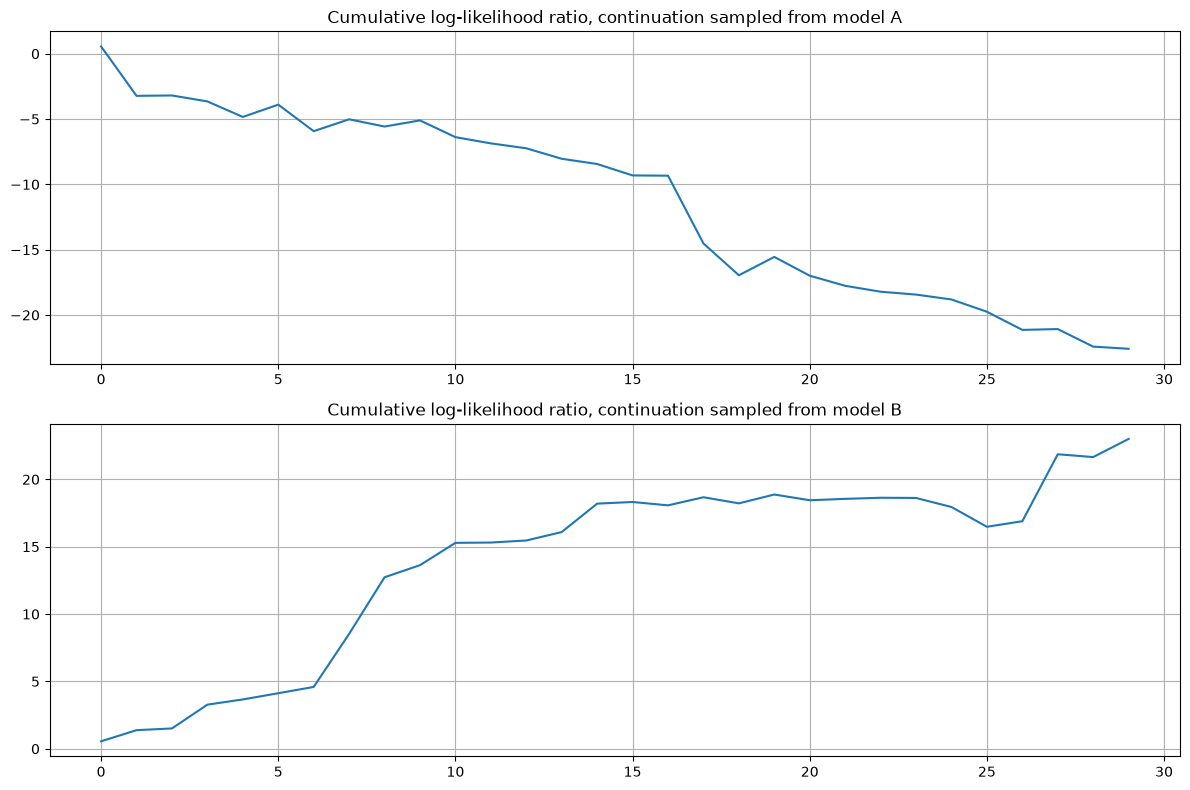

In [31]:
############################################
### Q5: cumulative log-likelihood ratios ###
############################################
prompt = "In statistics, a confidence interval is"
prompt_ids_A, continuationA = generate_ids(model_A, tokenizer_A, prompt, max_new_tokens=30)
prompt_ids_B, continuationB = generate_ids(model_B, tokenizer_B, prompt, max_new_tokens=30)

llr_modelA = log_likelihood_ratio_from_ids(prompt_ids_A, continuationA)
llr_modelB = log_likelihood_ratio_from_ids(prompt_ids_B, continuationB)

fig, ax= plt.subplots(2,1, figsize=(12,8))
ax[0].plot(np.cumsum(llr_modelA))
ax[0].set_title("Cumulative log-likelihood ratio, continuation sampled from model A")
ax[0].grid(True)

ax[1].plot(np.cumsum(llr_modelB))
ax[1].set_title("Cumulative log-likelihood ratio, continuation sampled from model B")
ax[1].grid(True)

plt.tight_layout()
plt.show()



#### Results (Q5)

- **Continuation sampled from $A$.** The cumulative log-likelihood ratio $\sum_t \log\big(p_{t,B}(x_t)/p_{t,A}(x_t)\big)$ decreases almost steadily and reaches about $-22.5$ after 30 tokens. This corresponds to a likelihood ratio of order $e^{-22}$, i.e. overwhelming evidence in favour of $A$: $H_0$ is not rejected.
- **Continuation sampled from $B$.** The cumulative log-likelihood ratio increases to about $+23$. The evidence for $B$ is strong, and $H_0$ is rejected for any reasonable threshold.
- **Why the trajectories drift.** Under the true model $M$, each increment has a conditional expectation equal to a Kullback–Leibler divergence. This expectation is $-\mathrm{KL}(p_{t,A}\,\|\,p_{t,B})\le 0$ under $A$ and $+\mathrm{KL}(p_{t,B}\,\|\,p_{t,A})\ge 0$ under $B$. Hence the opposite, roughly linear trends, with occasional large single-token jumps.

These are single realisations. Their sampling variability is quantified in Q6.

In [32]:
#####################################
### Q6 (a, b, c, d): Monte Carlo study ###
#####################################

def simulate_lr_paths(prompt, max_tokens, n_texts, generator_model, generator_tokenizer, seed):
    """Simulate texts and return the successive cumulative sums of T_AB.

    A single generation of length max_tokens is enough to study
    several lengths n, by using the prefixes of each text.
    """
    T_AB=[]
    for i in range(n_texts):
        prompt_ids, continuation_ids = generate_ids(generator_model, generator_tokenizer, prompt, max_new_tokens=max_tokens, seed=seed+i)
        llr = log_likelihood_ratio_from_ids(prompt_ids, continuation_ids)
        cumsum = np.cumsum(llr.detach().cpu().numpy())
        T_AB.append(cumsum)

    return T_AB




alpha = 0.05
N_CAL = 20
N_TEST = 20
LENGTHS = [10, 20, 30]
N_TOKENS = max(LENGTHS)
prompt = "In statistics, a confidence interval is"


# Protocol:
# - generate calibration trajectories under A;
# - generate independent test samples under A and under B;
# - compute the threshold, the level and the power for n=30;
# - repeat for each n in LENGTHS, recalibrating the threshold;
# - plot the level and the power as functions of n.

T_Cal = np.array(simulate_lr_paths(prompt, N_TOKENS, N_CAL, model_A, tokenizer_A, 42))
T_A = np.array(simulate_lr_paths(prompt, N_TOKENS, N_TEST, model_A, tokenizer_A, 2026))
T_B = np.array(simulate_lr_paths(prompt, N_TOKENS, N_TEST, model_B, tokenizer_B, 2027))



In [33]:
print("For n=30:")

k_alpha = np.quantile(T_Cal[:, N_TOKENS-1], 1-alpha)
print("threshold k_alpha = ", k_alpha)

level = np.mean(T_A[:, N_TOKENS-1] > k_alpha)
power = np.mean(T_B[:, N_TOKENS-1] > k_alpha)

print("level = ", level)
print("power = ", power)


For n=30:
threshold k_alpha =  -9.147962
level =  0.35
power =  1.0


In [34]:
# For several values of n, recalibrating the threshold each time:
values_dic = {}
for n in LENGTHS:
    print("n=",n)

    k_alpha = np.quantile(T_Cal[:, n-1], 1-alpha)


    level = np.mean(T_A[:, n-1] > k_alpha)
    power = np.mean(T_B[:, n-1] > k_alpha)
    values_dic[n]=[k_alpha, level, power]

    print("threshold k_alpha = ", k_alpha)
    print("level = ", level)
    print("power = ", power)

    print("=====")


n= 10
threshold k_alpha =  -0.7154663
level =  0.1
power =  0.95
=====
n= 20
threshold k_alpha =  -5.7889833
level =  0.1
power =  1.0
=====
n= 30
threshold k_alpha =  -9.147962
level =  0.35
power =  1.0
=====


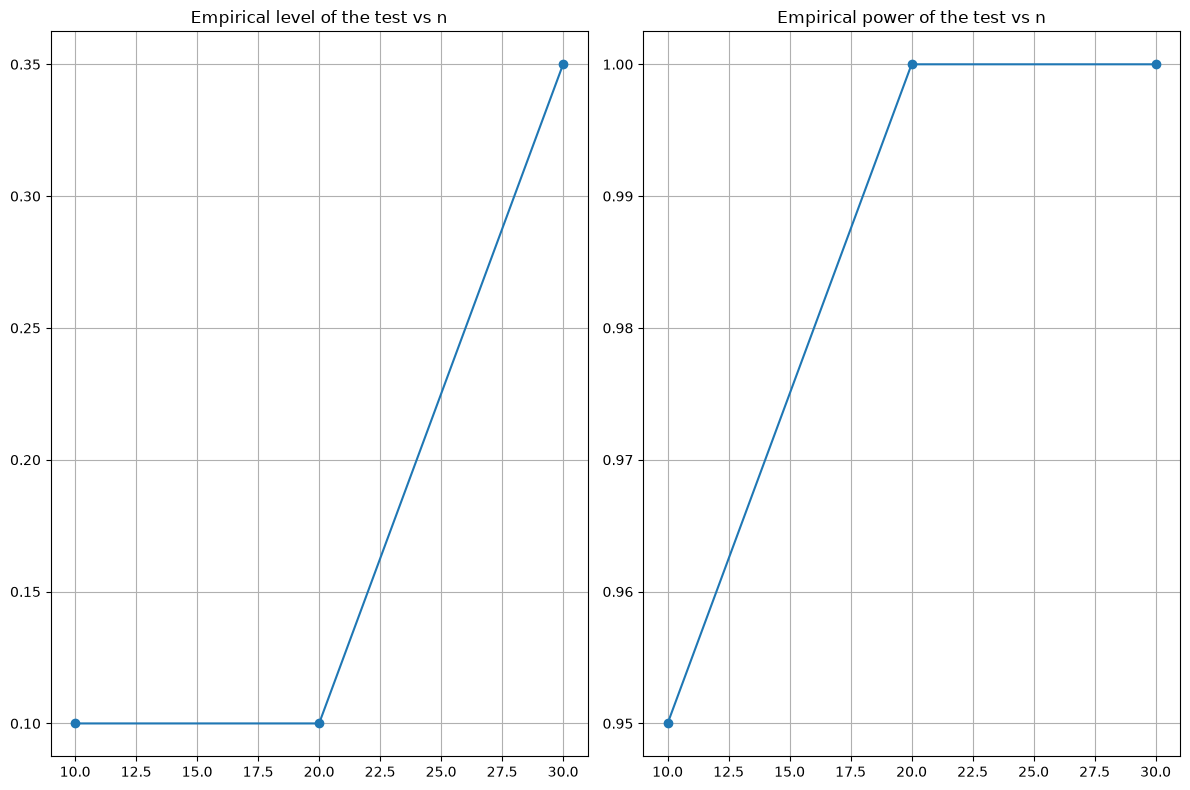

In [35]:
fig, ax = plt.subplots(1,2, figsize=(12,8))

levels = [values_dic[n][1] for n in LENGTHS]
ax[0].plot(LENGTHS, levels, marker="o")
ax[0].grid(True)
ax[0].set_title("Empirical level of the test vs n")

powers = [values_dic[n][2] for n in LENGTHS]
ax[1].plot(LENGTHS, powers, marker="o")
ax[1].grid(True)
ax[1].set_title("Empirical power of the test vs n")

plt.tight_layout()
plt.show()

#### Results (Q6 a–e)

Calibration uses $N_{\text{cal}}=20$ continuations from $A$ (seed 42). Evaluation uses two independent samples of 20 continuations from $A$ (seed 2026) and from $B$ (seed 2027). The nominal level is $\alpha=0.05$.

| $n$ | threshold $\hat k_{0.05,n}$ (log scale) | empirical level | empirical power |
|---|---|---|---|
| 10 | $-0.715$ | 0.10 | 0.95 |
| 20 | $-5.789$ | 0.10 | 1.00 |
| 30 | $-9.148$ | 0.35 | 1.00 |

- **(a)** For $n=30$, the calibrated threshold is $\hat k_{0.05}\approx -9.15$ on the log scale. It is negative because, under $A$, $T_{AB}$ drifts downward (see Q5).
- **(b)** Reading the final values in the Q5 figure, the continuation from $A$ ($T_{AB}\approx-22.5$) falls below the threshold and is not rejected. The continuation from $B$ ($T_{AB}\approx+23$) lies far above it and is rejected. Both decisions are correct.
- **(c)** At $n=30$, the empirical power is 1.00 (20/20 texts from $B$ rejected). The empirical level, however, is 0.35 (7/20 texts from $A$ rejected), far above the nominal 0.05. The level is therefore **not controlled** with this calibration. With only 20 calibration samples, the empirical 95% quantile is determined by the one or two largest values and is very unstable. In addition, a level estimated from 20 test texts has a resolution of 0.05 and a standard error of about 0.05 even at the nominal value.
- **(d)** Power increases with $n$ (0.95 at $n=10$, 1.00 for $n\ge 20$), as expected, because evidence accumulates linearly in $n$. The thresholds decrease with $n$, consistently with the downward drift of $T_{AB}$ under $H_0$. The empirical level (0.10, 0.10, 0.35) shows no interpretable trend in $n$: it is dominated by Monte Carlo noise in the calibration step rather than by the length.
- **(e)** If the same sample were used for calibration and evaluation, about a fraction $\alpha$ of it would exceed the threshold by construction. The estimated level would then merely reproduce $\alpha$ and would be optimistically biased, saying nothing about new texts. An independent evaluation sample gives an unbiased estimate of the actual level of the calibrated test. Here, calibration and evaluation use different random seeds.

In [36]:
def parse_token_ids(value):
    """Convert the JSON column `token_ids` of a CSV file into a tensor (1, n)."""
    return torch.tensor([json.loads(value)], dtype=torch.long)

def classify_ab_csv(csv_path, threshold):
    """Compute T_AB and the A/B decision for a blind file."""
    data = pd.read_csv(csv_path)
    rows = []

    for _, row in data.iterrows():
        prompt_ids = encode_prompt(tokenizer_A, row["prompt"]).detach().cpu()
        continuation_ids = parse_token_ids(row["token_ids"])
        score = float(log_likelihood_ratio_from_ids(prompt_ids, continuation_ids).sum())
        rows.append({"id": row["id"], "T_AB": score, "decision": "Reject H0 (B)" if score > threshold else "Do not reject H0 (A)"})

    return pd.DataFrame(rows)

########################################
### Q6 (f): classification of a blind file ###
########################################

csv_path = "data/phrases_AB.csv"
print(f"threshold used: k_alpha = {k_alpha}")
classify_ab_csv(csv_path, k_alpha)

threshold used: k_alpha = -9.147961616516113


,id,T_AB,decision
0,AB_01,16.126221,Reject H0 (B)
1,AB_02,-24.306610,Do not reject H0 (A)
2,AB_03,21.813263,Reject H0 (B)
3,AB_04,-3.509766,Reject H0 (B)
4,AB_05,-19.003387,Do not reject H0 (A)
5,AB_06,11.043671,Reject H0 (B)
6,AB_07,-7.046143,Reject H0 (B)
7,AB_08,-16.084839,Do not reject H0 (A)
8,AB_09,41.227539,Reject H0 (B)
9,AB_10,-17.902344,Do not reject H0 (A)


#### Results (Q6 f)

The test uses the threshold calibrated for $n=30$, $\hat k_{0.05}\approx-9.148$. Eight of the twelve continuations are attributed to $B$ (AB_01, 03, 04, 06, 07, 09, 11, 12), and four are attributed to $A$ (AB_02, 05, 08, 10).

- Most scores lie far from the threshold, with $|T_{AB}|\ge 8$, so those decisions are clear-cut.
- AB_04 ($-3.51$) and AB_07 ($-7.05$) have a negative log-likelihood ratio, so they are *more* likely under $A$ than under $B$. They are nevertheless attributed to $B$ because the calibrated threshold is negative. Given the inflated empirical level found in (c), these two decisions are the least reliable.
- The threshold was calibrated for one prompt and for continuations of length 30. It is valid for the file only if its continuations share these characteristics, which was not checked here.
- The true labels are not available, so the accuracy of these decisions cannot be assessed.

# 3. Tournament-sampling watermark (SynthID algorithm)

From now on, model $A$ is fixed. To speed up computations, at each position we keep only the $k=50$ most likely tokens under $A$ and renormalise their probabilities. In Sections 3 and 4, this truncated and renormalised distribution is still denoted $p_t$.

At position $t$, a deterministic pseudo-random function assigns a bit to each candidate token $v$ and each layer $\ell\in\{0,\ldots,d-1\}$:
$$
g_{t,\ell}(v)\in\{0,1\}.
$$
The bit is obtained by hashing (SHA-256) the string `"key|t|context|l|v"`, where:
- `key` is the private key;
- `t` is the token index;
- `context` contains the identifiers of the last 8 tokens;
- `l` is the layer;
- `v` is the identifier of the candidate token.

The first byte of the digest is then reduced modulo 2.

Two helper functions are provided below.

In [37]:
TOP_K = 50
WATERMARK_KEY = "statistics-course-watermark"

def topk_distribution_A(input_ids, top_k = TOP_K, temperature = 1.0):
    """Renormalised top-k distribution of model A.

    Parameters
    ----------
    input_ids : tensor of input token ids
    top_k : number of tokens kept in the distribution
    temperature : sampling temperature

    Returns
    -------
    distribution : (token ids, probabilities) of the next token
    """
    return next_token_distribution(model_A, input_ids.to(device), temperature = temperature, top_k = top_k)

def hashage(message):
    """SHA-256 hash, as bytes.

    Parameters
    ----------
    message : string to hash

    Returns
    -------
    hash : bytes of the SHA-256 digest of the message
    """
    return hashlib.sha256(message.encode()).digest()

### Q7 — Pseudo-random bit function

- **(a)** Why is $g_{t,\ell}$ chosen to be pseudo-random and deterministic, rather than truly random at each call?
- **(b)** Implement `g_values`.

#### Answer (Q7 a)

The bits must be **reproducible** by whoever holds the private key. Because $g_{t,\ell}$ is a deterministic function of (key, position, context, layer, token), anyone with the key and the generated text can recompute exactly the same sequence of bits $g_{t,\ell}$ at every position, without access to the random draws made during generation. This is what makes it possible to detect whether a text was actually generated by the watermarked model $A$. A truly random bit at each call could not be recomputed afterwards.

The bits are also **pseudo-random**: they are derived from a cryptographic hash of a secret key. Without the key, they therefore look like fair coin flips.

In [38]:
def g_values(token_ids, context_ids, layer = 0, key = WATERMARK_KEY):
    """Compute the pseudo-random bits associated with candidate tokens.

    Parameters
    ----------
    token_ids : list of candidate token ids
    context_ids : list of context token ids
    layer : tournament layer l
    key : watermark key

    Returns
    -------
    bits : numpy array of integers (0 or 1), one pseudo-random bit per candidate token
    """

    context_ids = list(map(int, context_ids))
    recent = tuple(context_ids[-8:])

    t = len(context_ids)

    result = []
    for token_id in token_ids:
        message = f"{key}|{t}|{recent}|{layer}|{int(token_id)}"

        # Bit = first byte of the SHA-256 digest, reduced modulo 2.
        bit = int(hashage(message)[0])%2
        result.append(bit)
    return np.asarray(result, dtype = int)


### Q8 — A single match

Fix a context and drop the index $t$. Take $d=1$, so $\ell = 0$.

Draw $Y_1,Y_2\sim p$ independently. If their bits differ, keep the candidate whose bit equals $1$. If the bits are equal, pick one of the two candidates uniformly at random. Let $q(v)$ denote the probability that $v$ is the winner.

- **(a)** With $m_0=\sum_{v:g(v)=0}p(v)$, derive $q(v)$.
- **(b)** Implement `one_tournament_distribution`.

#### Derivation (Q8 a)

Let $W\in\{1,2\}$ be the index of the selected candidate. Token $v$ wins if it is drawn in the slot that is selected, and these two events are disjoint:
$$q(v)=\mathbb P(W=1, Y_1=v)+\mathbb P(W=2, Y_2=v) = 2\,p(v)\,\mathbb P(W=1\mid Y_1=v),$$
where the second equality uses the symmetry between the two slots.

The quantity $m_0= \sum_{u: g(u)=0}p(u)$ is the probability that a token drawn from $p$ has bit $0$.

- **Case $g(v)=1$.** The first candidate is selected:
    * always, if the opponent has bit $0$ (probability $m_0$);
    * with probability $1/2$, if the opponent has bit $1$ (probability $1-m_0$).

  Therefore
  $$\mathbb{P}(W=1 \mid Y_1 = v) = m_0 \times 1 + (1 - m_0) \times \frac{1}{2} = \frac{1 + m_0}{2},
  \qquad\text{so}\qquad \boxed{q(v)=p(v)(1+m_0)}.$$

- **Case $g(v)=0$.** The first candidate is selected only if the opponent also has bit $0$ (probability $m_0$), and then with probability $1/2$:
  $$\mathbb{P}(W=1 \mid Y_1 = v)=\frac{m_0}{2},
  \qquad\text{so}\qquad \boxed{q(v)=p(v)\,m_0}.$$

**Check.** $\sum_v q(v) = (1-m_0)(1+m_0) + m_0\cdot m_0 = 1$.

A single match multiplies the probability of tokens with bit $1$ by $1+m_0\ge 1$ and that of tokens with bit $0$ by $m_0\le 1$.

In [39]:
def one_tournament_distribution(p, g):
    """Exact distribution of the winner of a two-candidate match.

    Parameters
    ----------
    p : numpy array of probabilities, one per candidate
    g : numpy array of pseudo-random bits, one per candidate

    Returns
    -------
    q : probabilities of each candidate being the winner
    """
    # q(v) = p(v) * m_0 if g(v) = 0, and p(v) * (1 + m_0) if g(v) = 1 (see Q8 a).
    m_0=np.sum([p[v] for v in range(len(p)) if g[v]==0])
    q = [m_0*p[v] if g[v]==0 else p[v]*(1+m_0) for v in range(len(p))]

    return q


### Q9 — Tournament of depth $d$

Start from $2^d$ independent candidates drawn from $p_t$. At the first layer, pair them and use $g_{t,0}$ to keep one winner per pair. Repeat with $g_{t,1}$, then with the following layers, until a single token remains.

- **(a)** Why use a different function $g_{t,\ell}$ at each layer?
- **(b)** Implement `tournament_distribution`.
- **(c)** For the prompt used above, compare graphically the watermarked distributions of depth $1$, $2$ and $3$ on the 10 most likely tokens.
- **(d)** Implement `tournament_select`.
- **(e)** Quantify the distortion of the next-token distribution induced by the watermark. For two distributions $p$ and $q$ on the same support, the total-variation distance is
$$
d_{\mathrm{TV}}(p,q)=\frac12\sum_v |p(v)-q(v)|.
$$
Fix the context above and depth $d=2$. For $R$ different watermark keys, compute the watermarked distributions $q^{(1)},\ldots,q^{(R)}$ and the distances $d_{\mathrm{TV}}(p,q^{(r)})$. Then compare the average
$$
\overline q=\frac1R\sum_{r=1}^R q^{(r)}
$$
to $p$. Discuss the distortion for a fixed key and the possible existence of a systematic bias towards particular tokens.

#### Answer (Q9 a)

A different function $g_{t,\ell}$ is used at each layer $\ell$ to keep the tournament "fair", i.e. to make the successive rounds independent.

If the same function were used at every layer, a token with bit $1$ in the first round would also have bit $1$ in every later round. It would win every match against a bit-$0$ token, so its advantage would be compounded at each layer, and the outcome would be driven by a single bit per token. The probabilistic structure of the scheme would break down. Layer-specific functions provide $d$ (approximately) independent bits per token.

In [40]:
def tournament_distribution(p, token_space, context_ids, depth, key = WATERMARK_KEY):
    """Exact distribution of the winner after `depth` tournament layers.

    Parameters
    ----------
    p : numpy array of probabilities, one per candidate
    token_space : list of candidate token ids
    context_ids : list of context token ids
    depth : number of tournament layers = d
    key : watermark key

    Returns
    -------
    q : probabilities of each candidate being the final winner
    """
    q = p.copy()

    # One match per layer, each with its own bit function g_{t,l}.
    for l in range(depth):
        g = g_values(token_space, context_ids, layer = l, key=key)
        q = one_tournament_distribution(q,g)

    return q 

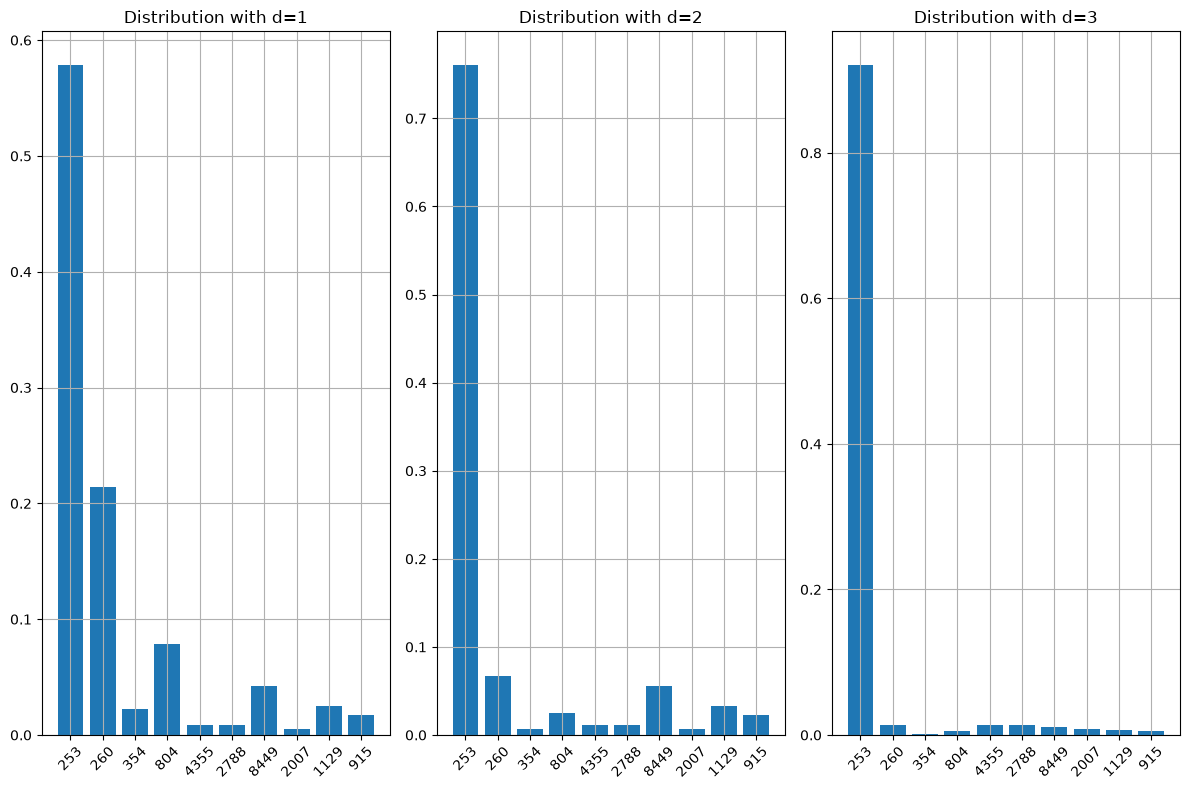

In [41]:
####################################################
### Q9 (c): watermarked distributions for d = 1, 2, 3 ###
####################################################
prompt_ids = encode_prompt(tokenizer_A, prompt)
tokens_id, p = next_token_distribution(model_A, prompt_ids, top_k=10)

context_ids = prompt_ids[0].detach().cpu().int().numpy()
q1 = tournament_distribution(p, tokens_id, context_ids, depth=1)
q2 = tournament_distribution(p, tokens_id, context_ids, depth=2)
q3= tournament_distribution(p, tokens_id, context_ids, depth=3)

fig, ax = plt.subplots(1,3, figsize=(12,8))

x_pos=range(len(tokens_id))

ax[0].bar(x=x_pos, height=q1)
ax[0].set_title("Distribution with d=1")
ax[0].set_xticks(x_pos)
ax[0].set_xticklabels(tokens_id, rotation=45)
ax[0].grid(True)

ax[1].bar(x=x_pos, height=q2)
ax[1].set_title("Distribution with d=2")
ax[1].set_xticks(x_pos)
ax[1].set_xticklabels(tokens_id, rotation=45)
ax[1].grid(True)

ax[2].bar(x=x_pos, height=q3)
ax[2].set_title("Distribution with d=3")
ax[2].set_xticks(x_pos)
ax[2].set_xticklabels(tokens_id, rotation=45)
ax[2].grid(True)

plt.tight_layout()
plt.show()

#### Observations (Q9 c)

*Implementation note.* The figure was produced from the renormalised **top-10** distribution of $A$ (`top_k=10`), not the top-50 distribution used elsewhere in Sections 3–4. It shows the watermarked distributions $q_1, q_2, q_3$. The reference $p_t$ is not plotted: it is the top-10 renormalisation of the probabilities printed in Experiment 1 for model $A$.

- Under $p_t$, the most likely token " a" (id 253) has probability $\approx 0.48$. With the default key, its probability increases to about $0.58$ ($d=1$), $0.76$ ($d=2$) and $0.92$ ($d=3$), as read from the figure.
- Other tokens may gain at one layer and lose at the next. The second token " the" (id 260), for example, has probability $\approx 0.18$ under $p_t$, about $0.21$ at $d=1$, then about $0.07$ at $d=2$ and $0.01$ at $d=3$.
- Increasing the depth concentrates the mass on the tokens that win the successive layers. The watermark signal per token grows with $d$, but for a fixed key so does the distortion of the distribution, and the diversity of the generated text decreases accordingly. Which tokens are favoured depends on the key (see Q9 e).

In [42]:
def tournament_select(candidate_ids, context_ids, depth, rng):
    """Explicitly run the tournament over 2**depth candidates.

    Parameters
    ----------
    candidate_ids : list of candidate token ids
    context_ids : list of context token ids
    depth : number of tournament layers
    rng : numpy random generator (e.g. rng = np.random.default_rng(71))

    Returns
    -------
    winner : id of the token that wins the tournament
    """

    current = list(map(int, candidate_ids))

    if len(current) != 2**depth:
        raise ValueError("Exactly 2**depth candidates are required.")

    for layer in range(depth):
        g = g_values(current, context_ids, layer=layer)
        next_round = []

        for i in range(0, len(current), 2):
            left = current[i]
            right = current[i + 1]

            # The candidate with bit 1 wins; ties are broken uniformly at random.
            if g[i] == 1 and g[i + 1] == 0:
                winner = left
            elif g[i] == 0 and g[i + 1] == 1:
                winner = right
            else:
                winner = int(rng.choice([left, right]))

            next_round.append(winner)

        current = next_round

    return current[0]




In [43]:
##############################################
### Q9 (e): distortion across watermark keys ###
##############################################

def total_variation(p, q):
    """Total-variation distance d_TV(p, q) = 1/2 * sum_v |p(v) - q(v)|."""
    distance = 0.5*np.sum(np.abs(p-q))
    return distance


DEPTH_DISTORTION = 2
N_KEYS = 100
keys = [f"statistics-course-watermark-{r}" for r in range(N_KEYS)]

# For each key:
# 1. compute the watermarked distribution q;
# 2. compute the distance between p and q.
#
# Then compute the key-averaged distribution q_bar
# and compare q_bar with p.

Q = []
distances = []
for key in keys:
    q = tournament_distribution(p, tokens_id, context_ids, depth=2, key=key)
    Q.append(q)
    distances.append(total_variation(p,q))

q_bar = np.mean(Q, axis=0)

distances = np.array(distances)
print(f"d_TV(p, q_r) over {N_KEYS} keys: min = {distances.min():.3f}, mean = {distances.mean():.3f}, max = {distances.max():.3f}")
print(f"d_TV(p, q_bar) = {total_variation(q_bar, p):.3f}")




#### Results (Q9 e)

$R=100$ keys, $d=2$, same top-10 context.

$$\min_r d_{\mathrm{TV}}(p,q^{(r)}) = 0.073,\qquad \frac1R\sum_{r=1}^R d_{\mathrm{TV}}(p,q^{(r)}) = 0.24,\qquad \max_r d_{\mathrm{TV}}(p,q^{(r)}) = 0.437$$

$$d_{\mathrm{TV}}(p,\overline q) = 0.018 \;\approx\; \frac{0.24}{13}$$

- **Fixed key:** the watermark substantially modifies the next-token distribution.
- **Average over keys:** the distortion is about 13 times smaller. The residual is compatible with the finite number of keys.
- **Interpretation:** no systematic bias towards particular tokens, consistent with the unbiasedness of tournament sampling for fair bits independent across layers (Dathathri et al., 2024):
$$\mathbb E_{\text{key}}[q(v)] = p(v).$$
- *Scope:* a single context, a 10-token support and 100 keys.

# 4. Likelihood-ratio test: watermarked vs unwatermarked generation

We now compare two generation mechanisms. Both rely on the same model $A$ and the same top-$k$ truncation:
$$
\begin{aligned}
H_0&:\text{at each position, the token is drawn from }p_t,\\
H_1&:\text{at each position, the token is drawn from }q_{t,d}.
\end{aligned}
$$
The prompt, the depth $d$ and the watermark key are fixed. At each position, $p_t$ and $q_{t,d}$ are recomputed from the context actually observed.

### Q10 — Generation and likelihood ratio

- **(a)** Implement `generate_topk_ids`, which samples either from $p_t$ (`mode="plain"`) or through a tournament (`mode="tournament"`).
- **(b)** Generate one continuation without watermark and one with a watermark of depth $d=2$. Using the provided function `watermark_log_lr_from_ids`, plot both cumulative log-likelihood ratios token by token.

In [44]:
@torch.no_grad()
def generate_topk_ids(prompt, max_new_tokens = 30, mode = "plain", depth = 2, seed = 0, top_k = TOP_K):
    """Generate a continuation with model A, with or without the tournament watermark.

    Parameters
    ----------
    prompt : text used as context
    max_new_tokens : maximum number of tokens to generate
    mode : "plain" for top-k sampling, "tournament" for tournament sampling
    depth : depth of the tournament
    seed : seed of the random generator
    top_k : number of tokens kept for top-k sampling

    Returns
    -------
    prompt_ids : tensor (1, L) containing the token ids of the prompt
    continuation_ids : tensor (1, L') containing the token ids of the generated continuation
    """
    rng = np.random.default_rng(seed)

    input_ids = encode_prompt(tokenizer_A, prompt)
    prompt_ids = input_ids.clone()
    generated = []

    for _ in range(max_new_tokens):
        token_space, p = next_token_distribution(model_A, input_ids, temperature = 1.0, top_k = top_k)
        context_ids = input_ids[0].tolist()

        # Sampling step: directly from p_t, or via a tournament over 2**depth candidates drawn from p_t.
        if mode == "plain":
            token = rng.choice(token_space, p=p / np.sum(p))
        elif mode == "tournament":
            candidates = rng.choice(token_space, size=2**depth, p=p / np.sum(p))
            token = tournament_select(candidates, context_ids, depth, rng)
        else:
            raise ValueError("mode must be 'plain' or 'tournament'.")

        generated.append(token)
        new_token = torch.tensor([[token]], dtype = input_ids.dtype, device = device)
        input_ids = torch.cat([input_ids, new_token], dim = 1)

    continuation_ids = torch.tensor([generated], dtype = prompt_ids.dtype)

    return prompt_ids.detach().cpu(), continuation_ids

@torch.no_grad()
def watermark_log_lr_from_ids(prompt_ids, continuation_ids, depth=2, top_k=TOP_K):
    """Increments log(q_{t,d}(x_t) / p_t(x_t)) along a continuation.

    Parameters
    ----------
    prompt_ids : tensor (1, L) containing the token ids of the prompt
    continuation_ids : tensor (1, L') containing the token ids of the continuation
    depth : depth of the tournament
    top_k : number of tokens kept for top-k sampling

    Returns
    -------
    increments : numpy array (L',) containing log(q_{t,d}(x_t) / p_t(x_t)) for each token of the continuation
    """
    prompt_ids = prompt_ids.to(device)
    continuation_ids = continuation_ids.to(device)
    full_ids = torch.cat([prompt_ids, continuation_ids], dim=1)
    prompt_length = prompt_ids.shape[1]

    # logits[:, j] predicts the token at position j+1.
    logits_all = model_A(full_ids).logits[0]
    increments = []

    for j in range(continuation_ids.shape[1]):
        position = prompt_length + j
        observed_token = int(full_ids[0, position])
        logits = logits_all[position - 1]

        values, token_ids = torch.topk(logits, k=top_k)
        p = torch.softmax(values, dim=-1).float().detach().cpu().numpy()
        token_space = token_ids.detach().cpu().numpy()

        where = np.flatnonzero(token_space == observed_token)
        if len(where) != 1:
            raise ValueError("The observed token is not in the top-k support: the text is not compatible with H0/H1 as defined here.")

        context_ids = full_ids[0, :position].detach().cpu().tolist()
        q = tournament_distribution(p, token_space, context_ids, depth)
        k = int(where[0])
        increments.append(np.log(q[k]) - np.log(p[k]))

    return np.asarray(increments)


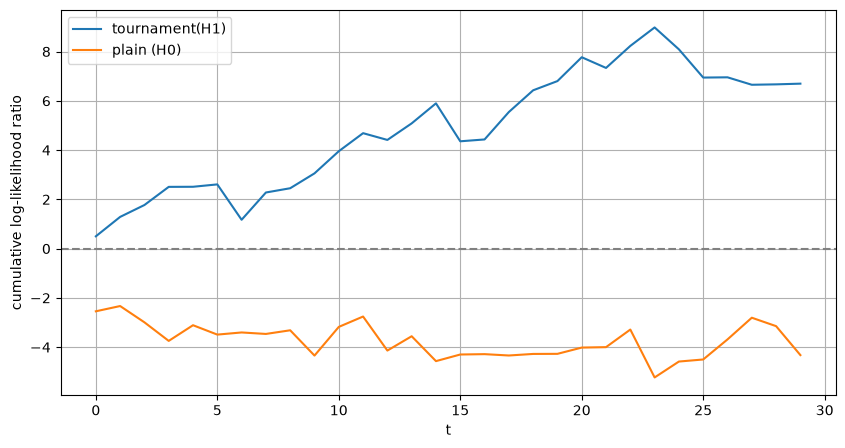

In [45]:
######################################################
### Q10 (b): watermarked vs plain log-likelihood ratio ###
######################################################

prompt_ids, tournament_continuation = generate_topk_ids(prompt, mode = "tournament")
_, plain_continuation = generate_topk_ids(prompt, mode="plain")

tournament_llr = np.cumsum(watermark_log_lr_from_ids(prompt_ids, tournament_continuation))
plain_llr = np.cumsum(watermark_log_lr_from_ids(prompt_ids, plain_continuation))

plt.figure(figsize=(10, 5))
plt.plot(tournament_llr, label="tournament(H1)")
plt.plot(plain_llr, label="plain (H0)")
plt.axhline(0, color="gray", linestyle="--")
plt.xlabel("t")
plt.ylabel("cumulative log-likelihood ratio")
plt.legend()
plt.grid(True)
plt.show()

#### Results (Q10 b)

Both continuations use the same prompt, top-$k=50$, depth $d=2$ and seed 0. The figure shows the cumulative statistic $\sum_t \log\big(q_{t,2}(x_t)/p_t(x_t)\big)$.

- **Watermarked continuation ($H_1$).** The statistic increases overall. It reaches about $9$ around the 24th token and ends at about $6.7$ after 30 tokens. The trajectory is not monotone: some selected tokens have $q_{t,2}(x_t) < p_t(x_t)$.
- **Unwatermarked continuation ($H_0$).** The statistic is negative from the first token, at about $-2.5$. It then fluctuates between about $-2.3$ and $-5.2$ and ends at about $-4.3$.
- The two trajectories are separated from the very first tokens, and a threshold at $0$ would classify both correctly. As in Section 2, the drifts reflect the sign of the expected increments: $\mathrm{KL}(q_{t,d}\,\|\,p_t)\ge0$ under $H_1$ and $-\mathrm{KL}(p_t\,\|\,q_{t,d})\le0$ under $H_0$.
- Only one realisation per hypothesis was drawn and no threshold was calibrated, so level and power are not quantified here.
- This test requires full access to model $A$, i.e. to $p_t$ and $q_{t,d}$, at every position. This motivates the simpler detector of Section 5.

# 5. A key-based detector using the $g$ bits

The likelihood-ratio test of the previous section assumes that both generation mechanisms are known exactly. In practice, one would like a simpler detector that does not require recomputing the model's full probabilities at each position.

Fix a depth $d$ and observe a continuation of length $n$. For each position $t=1,\ldots,n$ and each layer $\ell=0,\ldots,d-1$, define
\begin{equation*}
    G_{t,\ell}=g_{t,\ell}(X_t)\in\{0,1\}.
\end{equation*}
This gives $nd$ bits in total, which are aggregated into
\begin{equation*}
    K_{n,d}=\sum_{t=1}^{n}\sum_{\ell=0}^{d-1}G_{t,\ell}.
\end{equation*}

We want to distinguish
$$
H_0:\text{ the continuation was not generated by $A$ with this watermark and this key,}
$$
from
$$
H_1:\text{ the continuation was generated by $A$ with this watermark and this key}.
$$
Under $H_0$, the text may be written by a human, produced by $A$ without watermark, produced by $B$, or come from any other model.

We make the following approximation: under $H_0$, the bits $G_{t, \ell}$ "behave like" i.i.d. $\mathrm{Bernoulli}(1/2)$ variables.

### Q11 — Binomial test

- **(a)** Why is the assumption that the $G_{t,\ell}$ are exactly i.i.d. $\mathrm{Bernoulli}(1/2)$ under $H_0$ only an idealised model? More generally, why is the test not fully specified until one states how texts are produced under $H_0$?
- **(b)** In the simplified model where the $nd$ variables $G_{t,\ell}$ are i.i.d. $\mathrm{Bernoulli}(1/2)$ under $H_0$, derive the law of $K_{n,d}$ under $H_0$. Propose a one-sided test detecting an excess of bits equal to $1$, and give the corresponding binomial $p$-value.
- **(c)** Implement functions computing $K_{n,d}$, the proportion $K_{n,d}/(nd)$ and the binomial $p$-value of the idealised model. Why is the proportion useful when texts have different lengths?

#### Answers (Q11)

**(a)** The assumption $G_{t,\ell} \sim \mathcal{B}(1/2)$ i.i.d. under $H_0$ presupposes two things: that the text is independent of the private key, and that $g$ behaves like a truly random function. A text produced under $H_0$ may, however, depend on the key. For example, a human may paraphrase a watermarked output of $A$, in which case the bits are biased towards $1$. More generally, the null distribution of $K_{n,d}$, and hence the rejection threshold, depends on how texts under $H_0$ are produced. Without restricting that class (at the very least to texts independent of the key), the level of the test is not defined.

**(b)** Under the idealised null model, $K_{n,d} \sim \mathrm{Bin}(nd,1/2)$, with $\mathbb E_{H_0}[K_{n,d}]=nd/2$ and $\mathrm{Var}_{H_0}(K_{n,d})=nd/4$.

Under $H_1$, the tournament favours tokens with bit $1$, so we use the one-sided test
$$\Phi(X)=\mathbf 1_{\{K_{n,d}\ge c_\alpha\}},$$
where $c_\alpha$ is the smallest integer such that $\mathbb P_{H_0}(K_{n,d} \ge c_\alpha) \le \alpha$. The distribution is discrete, so the level is at most $\alpha$.

If $K_{n,d}=k$ is observed, the $p$-value is the probability under $H_0$ of observing at least as many ones:
$$p(k)=\mathbb P_{H_0}(K_{n,d}\ge k)=2^{-nd}\sum_{j=k}^{nd}\binom{nd}{j}.$$
$H_0$ is rejected at level $\alpha$ if and only if $p(k)\le\alpha$, which is equivalent to $k\ge c_\alpha$.

**(c)** The cell below implements `g_matrix_from_ids` (bit matrix $G$), `g_bits_proportion` ($K_{n,d}/(nd)$) and `g_bits_statistic` ($K_{n,d}$, exact $p$-value, decision), with
$$p(k) = \mathbb P_{H_0}(K_{n,d}\ge k) = 1 - F_{\mathrm{Bin}(nd,1/2)}(k-1).$$

The count $K_{n,d}$ grows with the number of bits, whereas the proportion does not:
$$\mathbb E_{H_0}[K_{n,d}] = \frac{nd}{2}, \qquad \hat\pi = \frac{K_{n,d}}{nd},\quad \mathbb E_{H_0}[\hat\pi] = \frac12,\quad \mathrm{sd}_{H_0}(\hat\pi) = \frac{1}{2\sqrt{nd}} .$$
The proportion is therefore comparable across texts of different lengths. The $p$-value still has to use $K_{n,d}$ and $nd$: the same proportion is more significant on a longer text.

In [46]:
##################################
### Q11 (c): g-bit detector ###
##################################
from scipy.stats import binom

def g_matrix_from_ids(prompt_ids, continuation_ids, depth):
    """Recompute the matrix of bits g_{t,l}(X_t).

    Parameters
    ----------
    prompt_ids : tensor (1, L) containing the token ids of the prompt
    continuation_ids : tensor (1, L') containing the token ids of the continuation
    depth : depth of the tournament

    Returns
    -------
    bits : numpy array (L', depth) containing the bits g_{t,l}(X_t) for each continuation token and each tournament layer
    """

    context = list(map(int, prompt_ids[0].tolist()))
    tokens = list(map(int, continuation_ids[0].tolist()))
    bits = np.empty((len(tokens), depth), dtype=int)

    for t, token_id in enumerate(tokens):
        for l in range(depth):
            bits[t,l] =  g_values([token_id], context, layer=l)[0]
        # X_t becomes part of the context of X_{t+1}.
        context.append(token_id)

    return bits

def g_bits_proportion(bits):
    """Proportion of bits equal to 1, K_{n,d} / (nd)."""
    return np.sum(bits) / bits.size

def g_bits_statistic(id_num, bits):
    """Compute K, the p-value and the decision from the matrix of bits g_{t,l}(X_t).

    Parameters
    ----------
    id_num : text identifier (for display)
    bits : numpy array (L', depth) containing the bits g_{t,l}(X_t)

    Returns
    -------
    stats : dictionary with the id, K, the p-value and the decision
    """
    n,d = len(bits), len(bits[0])
    K = np.sum(bits)
    # p-value of Q11 (b): P(K' >= K) = 1 - F(K - 1), with K' ~ Bin(nd, 1/2) under H0.
    p_value = 1-binom.cdf(K-1, n*d, 0.5)
    if p_value < 0.05:
        decision = "reject H0"
    else:
        decision = "fail to reject H0"

    return {"id": id_num, "K": K, "p-value": p_value, "decision": decision}

### Q12 — Evaluation on a labelled file 

The file `phrases_filigrane.csv` contains two types of continuations:

- continuations generated by $A$ **with** the tournament and the key used in this notebook;
- **unwatermarked** continuations of various origins, e.g. $A$ without watermark, $B$, external text or another source.

The true class and the exact origin of the unwatermarked texts are hidden.

- **(a)** At level $\alpha = 0.05$, decide for each text between "generated by $A$ with watermark" and "other text".
- **(b)** Explain why the decisions must be interpreted with caution in the real-world problem. Does a small $p$-value give the probability that $H_1$ is true?

In [ ]:
def parse_token_ids(value):
    """Convert the JSON column `token_ids` into a tensor of shape (1, n).

    Parameters
    ----------
    value : string holding a JSON list of token ids

    Returns
    -------
    tensor : tensor (1, n) containing the token ids
    """
    return torch.tensor([json.loads(value)], dtype = torch.long)

#####################################################
### Q12 (a): classification of a labelled file ###
#####################################################

def classify_watermark_csv(csv_path, alpha = 0.05):
    """Apply the K detector to the provided CSV file.

    Parameters
    ----------
    csv_path : path to the CSV file containing the prompts and the token_ids
    alpha : significance level used for the decision

    Returns
    -------
    DataFrame : table with the results (K, p-value, decision) of the classification
    """
    data = pd.read_csv(csv_path)
    rows = []

    for _, row in data.iterrows():
        prompt_ids = encode_prompt(tokenizer_A, row["prompt"]).detach().cpu()
        continuation_ids = parse_token_ids(row["token_ids"])
        bits = g_matrix_from_ids(prompt_ids, continuation_ids, depth=int(row["depth"]))

        statistics = g_bits_statistic(row["id"], bits)

        rows.append(statistics)

    return pd.DataFrame(rows)

csv_path = "data/phrases_filigrane.csv"
classify_watermark_csv(csv_path)

,id,K,p-value,decision
0,G_01,82,0.000036,reject H0
1,G_02,57,0.738505,fail to reject H0
2,G_03,84,0.000007,reject H0
3,G_04,83,0.000016,reject H0
4,G_05,59,0.607836,fail to reject H0
5,G_06,57,0.738505,fail to reject H0
6,G_07,57,0.738505,fail to reject H0
7,G_08,80,0.000165,reject H0
8,G_09,58,0.675870,fail to reject H0
9,G_10,68,0.085323,fail to reject H0


#### Results (Q12)

$\alpha = 0.05$, $nd = 120$ bits per text, $\hat\pi = K/(nd)$.

| | texts | $K$ | $\hat\pi$ | $p$-value |
|---|---|---|---|---|
| reject $H_0$ (watermark detected) | G_01, G_03, G_04, G_08, G_11 | 80–86 | 0.667–0.717 | $\le 1.7\times10^{-4}$ |
| fail to reject $H_0$ | G_02, G_05, G_06, G_07, G_09, G_10, G_12 | 57–68 | 0.475–0.567 | $\ge 0.085$ |

- **(a)** 5 of the 12 texts are attributed to $A$ with watermark. The two groups are well separated: no text has $\hat\pi$ between $0.567$ and $0.667$. The detected texts lie inside the range expected under the watermark, $\mathbb E[\pi] = 1-\mathbb E[m_0^2] \in [0.5, 0.75]$.
- G_10 is the only borderline case: $K=68$, $\hat\pi = 0.567$, $p = 0.085$. It is not rejected at 5%. It may be a low-entropy watermarked text or an unwatermarked text with a high count by chance; the labels are needed to tell.
- **(b)** The decisions must be read with caution:
  - the level $\alpha$ is only valid under the idealised null (bits i.i.d. $\mathcal B(1/2)$, text independent of the key; see Q11 a). A paraphrase of a watermarked text, for instance, violates it;
  - 12 tests at level $0.05$: if all texts were unwatermarked, $12 \times 0.05 = 0.6$ false positives would be expected;
  - a $p$-value is $\mathbb P_{H_0}(K \ge k)$, not $\mathbb P(H_1 \mid K = k)$. The latter requires a prior $\pi_1 = \mathbb P(H_1)$ and the law of $K$ under $H_1$:
$$\mathbb P(H_1 \mid K=k) = \frac{\pi_1\, \mathbb P_{H_1}(K=k)}{\pi_1\, \mathbb P_{H_1}(K=k) + (1-\pi_1)\, \mathbb P_{H_0}(K=k)} .$$
  A small $p$-value says the data are unlikely under $H_0$, not that $H_1$ is likely.

# 6. Watermark removal and robustness to translation

This final part studies what happens to the statistical signal when a watermarked text is transformed by another model.

The starting point is any text generated by model $A$ with the watermark, either newly generated or taken from above. The same detector is applied before and after the transformation.

The transformation is a round-trip translation, English $\to$ French $\to$ English, performed with Google Translate. The $p$-values before and after the transformation are then compared.

### Q13 — Round-trip translation protocol.

In [ ]:
prompt = "A statistical hypothesis test is useful because"
DEPTH = 2
N_NEW_TOKENS = 60

prompt_ids, continuation_ids = generate_topk_ids(prompt, max_new_tokens=N_NEW_TOKENS, mode="tournament", depth=DEPTH, seed=0)
watermarked_text = tokenizer_A.decode(continuation_ids[0], skip_special_tokens=True)

bits = g_matrix_from_ids(prompt_ids, continuation_ids, depth=DEPTH)
initial_stats = g_bits_statistic("watermarked", bits)

_, plain_ids = generate_topk_ids(prompt, max_new_tokens=N_NEW_TOKENS, mode="plain", seed=0)
plain_bits = g_matrix_from_ids(prompt_ids, plain_ids, depth=DEPTH)
plain_stats = g_bits_statistic("plain", plain_bits)

print(f"Watermarked: share of 1s = {g_bits_proportion(bits):.3f}, p-value = {initial_stats['p-value']:.2e}")
print(f"Plain:       share of 1s = {g_bits_proportion(plain_bits):.3f}, p-value = {plain_stats['p-value']:.2e}")

In [56]:
print(watermarked_text)

 it provides a means to determine if a hypothesis should be rejected or not. A test that gives probabilities or probabilities to reject a hypothesis is the type of test that a statistician uses, and a test that gives scores on a scale of 0 - 10 gives scores on the same scale.


In [57]:
print("INITIAL ENGLISH TEXT TO TRANSLATE:")
print(watermarked_text)

ROUND_TRIP_TRANSLATION_EN = "It helps determine whether a hypothesis should be rejected or not. A test that gives probabilities, or the probabilities of rejecting a hypothesis, is the type of test used by a statistician; a test that gives scores on a scale of 0 to 10 gives scores on the same scale."

INITIAL ENGLISH TEXT TO TRANSLATE:
 it provides a means to determine if a hypothesis should be rejected or not. A test that gives probabilities or probabilities to reject a hypothesis is the type of test that a statistician uses, and a test that gives scores on a scale of 0 - 10 gives scores on the same scale.


In [ ]:
if ROUND_TRIP_TRANSLATION_EN is None:
    print("Paste the final English translation into ROUND_TRIP_TRANSLATION_EN first.")
else:
    prefix = " " if watermarked_text.startswith(" ") else ""
    translated_ids = encode_prompt(tokenizer_A, prefix + ROUND_TRIP_TRANSLATION_EN.strip()).detach().cpu()

    translated_bits = g_matrix_from_ids(prompt_ids, translated_ids, depth=DEPTH)
    translated_stats = g_bits_statistic("translated", translated_bits)

    print("Final English translation:")
    print(ROUND_TRIP_TRANSLATION_EN)
    print(f"\nBefore translation: share of 1s = {bits.mean():.3f}, {initial_stats}")
    print(f"After translation:  share of 1s = {translated_bits.mean():.3f}, {translated_stats}")

Final English translation:
It helps determine whether a hypothesis should be rejected or not. A test that gives probabilities, or the probabilities of rejecting a hypothesis, is the type of test used by a statistician; a test that gives scores on a scale of 0 to 10 gives scores on the same scale.

Before translation: share of 1s = 0.742, {'id': 'watermarked', 'K': np.int64(89), 'p-value': np.float64(5.5938609300199005e-08), 'decision': 'reject H0'}
After translation:  share of 1s = 0.381, {'id': 'translated', 'K': np.int64(45), 'p-value': np.float64(0.9963349900154654), 'decision': 'fail to reject H0'}


#### Results (Q13)

**Before translation** (60 tokens, $d=2$):

$$K = 89,\quad nd = 120,\quad \hat\pi = \frac{K}{nd} = 0.742,\quad p = \mathbb P_{H_0}(K \ge 89) = 5.6\times10^{-8} \;\Rightarrow\; \text{reject } H_0$$

With $m_0$ the probability of the tokens with bit $0$, the expected share of ones lies between $0.5$ (nearly fixed next token) and $0.75$ (very uncertain next token):

$$\mathbb E[\pi] = 1 - \mathbb E[m_0^2] \in [0.5,\ 0.75], \qquad \hat\pi = 0.742 \approx 0.75 .$$

The share is close to the maximum, so the text is high-entropy and the watermark signal is strong.

**After round-trip translation** (EN → FR → EN, Google Translate):

$$K = 45,\quad nd = 118,\quad \hat\pi = 0.381,\quad p = 0.996 \;\Rightarrow\; \text{fail to reject } H_0$$

| | $nd$ | $K$ | $\hat\pi$ | $p$-value | decision |
|---|---|---|---|---|---|
| original | 120 | 89 | 0.742 | $5.6\times10^{-8}$ | reject $H_0$, watermark detected |
| translated | 118 | 45 | 0.381 | 0.996 | fail to reject, no watermark detected |

The meaning is preserved, but the watermark is no longer detected. The plain continuation printed in the first Q13 cell gives the reference share without watermark.

**Why the signal disappears.** Each bit is
$$g_{t,\ell}(v) = \mathrm{SHA256}(\text{key} \,|\, t \,|\, x_{t-8:t-1} \,|\, \ell \,|\, v)_{[0]} \bmod 2 .$$
The first token changes (" it provides" → "It helps"), so the absolute position $t$ of every later token shifts. Every bit becomes a fresh coin flip, even inside unchanged phrases:
$$G_{t,\ell} \sim \mathcal B(1/2) \;\Rightarrow\; K \sim \mathrm{Bin}(118,\ 1/2).$$

**On the low share $\hat\pi = 0.381$.** $\mathbb P_{H_0}(K \le 45) = 0.006$. The watermark can only increase $K$, so a single text in the lower tail is consistent with chance and says nothing about the watermark.

**Limitations.** One text, one translation tool. The result is specific to a position-dependent hash: a context-only seed, as in SynthID, would keep part of the signal in passages copied word for word.

# 7. Conclusions

| Question | Result |
|---|---|
| A vs B (LR test, Section 2) | $T_{AB} \approx -22.5$ (text from $A$) and $+23$ (text from $B$) at $n=30$; power $0.95$ at $n=10$, $1.00$ for $n \ge 20$; empirical level $0.10$–$0.35$ for $\alpha = 0.05$ |
| Tournament watermark (Section 3) | $q(v) = p(v)(1+m_0)$ if $g(v)=1$, $p(v)\,m_0$ otherwise; $p(\text{" a"}) = 0.48 \to 0.92$ at $d=3$ |
| Distortion (Q9 e) | $d_{\mathrm{TV}}(p,q^{(r)}) = 0.24$ on average per key, $d_{\mathrm{TV}}(p,\overline q) = 0.018$ |
| Watermarked vs plain (LR test, Section 4) | cumulative log-LR $+6.7$ vs $-4.3$ after 30 tokens |
| Key-only binomial test (Q12) | 5/12 texts detected, $\hat\pi \in [0.667, 0.717]$, $p \le 1.7\times10^{-4}$; others $\hat\pi \in [0.475, 0.567]$ |
| Round-trip translation (Q13) | $\hat\pi$: $0.742 \to 0.381$, $p$: $5.6\times10^{-8} \to 0.996$ |

- **Detection works on short texts.** With full model access, both LR tests separate the hypotheses within 10–30 tokens. With the key only, 60 tokens give $p \approx 10^{-8}$ on a high-entropy text.
- **The watermark is unbiased on average.** It distorts each next-token distribution for a fixed key but favours no token on average over keys.
- **The A/B test is miscalibrated.** With $N_{\mathrm{cal}} = 20$, the empirical level reaches $0.35$ for $\alpha = 0.05$. A much larger calibration sample is needed.
- **The watermark is fragile in this implementation.** A meaning-preserving translation removes it completely, because the hash depends on the absolute position.

**Limitations.** Small models, one prompt per experiment, small Monte Carlo samples, single realisations in Q5, Q10 and Q13, idealised null hypothesis for the binomial test, no labels for the blind files.

**Next steps.** Recalibrate the A/B test with a larger sample; replace the position by a context-only seed and repeat the translation experiment; evaluate the binomial test on labelled data to estimate its level and power.

### References

- S. Dathathri et al., "Scalable watermarking for identifying large language model outputs", *Nature*, vol. 634, pp. 818–823, 2024. https://doi.org/10.1038/s41586-024-08025-4
- Google DeepMind, reference implementation `synthid-text`: https://github.com/google-deepmind/synthid-text
- Hugging Face, SmolLM2 models: `HuggingFaceTB/SmolLM2-135M`, `HuggingFaceTB/SmolLM2-360M`.
- Problem statement adapted from the course APM41033, École polytechnique (A. Dieuleveut): https://www.cmap.polytechnique.fr/~aymeric.dieuleveut/APM41033/